# 3D airspace conductance (gias) of a sorghum leaf from deposited microCT ML stacks

Reproduction of the airspace-conductance analysis in:

**Fischer et al., "High-resolution microCT reveals relationships between stomata and interior leaf
anatomy in sorghum", *Plant Physiology* 201(3): kiag414 (2026).**
DOI: [10.1093/plphys/kiag414](https://doi.org/10.1093/plphys/kiag414) •
PMC: [PMC13421375](https://pmc.ncbi.nlm.nih.gov/articles/PMC13421375/) •
Code: [leakey-lab/microCT-Macros-Fischer](https://github.com/leakey-lab/microCT-Macros-Fischer) @ `9d7fcd2f417b9af686bf55a2ff81616adb316c4d` •
Data: [Illinois Data Bank IDB-8233295](https://doi.org/10.13012/B2IDB-8233295_V1) (CC BY)

**Scope (one sample, partial demonstration).** The paper's full pipeline (Mask R-CNN segmentation →
crypt isolation → conductance traits → statistics) is reduced to its published measurement core for
**one deposited leaf sub-sample**: using the already ML-labeled stack and stomatal-dot stack, we
compute the mesophyll:airspace contact, the geodesic/euclidean path-length maps (Lgeo, Leuc, Lepi),
tortuosity τ (Eq 4), lateral path lengthening λ (Eq 5), porosity θ (Eq 1), and the resulting
airspace CO₂ conductance **gias** (Eqs 6–7), split into adaxial (AD) and abaxial (AB) regions using
the author's vascular-centroid rule (MACRO_1). Mask R-CNN segmentation is **not** re-run (no public
weights); crypt isolation (MACRO_2), depth-profile statistics (MACRO_3C, nlme) and figure macros
(4A–4E) are out of scope.

> **⚠ AI-assisted translation — read first / ＊最初にお読みください**
> The authors released this analysis as **ImageJ/Fiji macros (IJM)**, not as a Colab notebook. The
> cells below are an **AI-assisted Python translation of the author's IJM logic and the paper's
> Eqs 1–8**; the authors did not provide this Colab implementation. Headless reuse of the author's
> macros (Fiji + MorphoLibJ) was assessed in a diagnostic run and is impractical for these stack
> sizes on a standard Colab CPU runtime (a ≥5×10⁸-voxel 3-D geodesic), and even a Dijkstra-based
port needed a graph formulation to fit the runtime budget. The
> executed example and listed checks were validated on Colab, but untested behavior is not
> guaranteed, and results are for the demonstration subvolume, not full-sample paper values.
>（著者のマクロを AI が Python へ翻訳したものです。著者提供の Colab 実装ではありません。）

**Runtime: CPU only.** No GPU code path exists in this analysis; select
`ランタイム → ランタイムのタイプを変更 → CPU` (or leave the default). Run all cells top to bottom
(`ランタイム → すべてのセルを実行`). Expected: ~1.0 GB download + ~3.6 GB extracted stacks, and
roughly 15–30 minutes total on a standard Colab CPU runtime (measured values are printed by the
timing cells). All data stays under `/content`.

**Environment check.** The scientific stack (numpy, scipy, scikit-image, tifffile, pandas,
matplotlib) is preinstalled on current Colab runtimes; we verify versions and fail loudly if
anything essential is missing rather than silently proceeding.
（必要なライブラリが Colab に揃っているかを確認します。）

In [ ]:
import sys, platform, importlib, os
print("python:", sys.version.split()[0], "|", platform.platform())
required = ["numpy", "scipy", "skimage", "tifffile", "pandas", "matplotlib"]
for m in required:
    mod = importlib.import_module(m)
    print(f"{m}=={mod.__version__}")
import psutil
print("RAM GB: %.2f | CPUs: %d" % (psutil.virtual_memory().total / 2**30, os.cpu_count()))

python: 3.13.16 | Linux-6.6.159+-x86_64-with-glibc2.39
numpy==2.1.3
scipy==1.16.3
skimage==0.25.2


tifffile==2026.10.15


pandas==2.2.3
matplotlib==3.10.0
RAM GB: 12.67 | CPUs: 2


**Download the paper's data deposit** (Illinois Data Bank `IDB-8233295`, license CC BY) inside
Colab: only `ML_STACKS.zip` (26 leaf sub-samples × {ML-labeled stack, stomatal-dot stack}) is
needed; the raw-scan archive (32.8 GB) is not used because segmentation is not re-run. We verify
the ZIP signature and SHA-256 (measured for this deposit) and stream progress.
（論文のデータ一式を Colab 内にダウンロードし、署名と SHA-256 を検証します。）

In [ ]:
import hashlib, subprocess
URL = "https://databank.illinois.edu/datafiles/nx7mv/download"
SHA256 = "14ad096ba2e9c448c1647feabebb29eeb2c98f382118f462ae739a59ae2a0fd5"
dst = "/content/ML_STACKS.zip"
ua = "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/126.0 Safari/537.36"
if not (os.path.exists(dst) and os.path.getsize(dst) > 900_000_000):
    try:
        import requests
        with requests.get(URL, headers={"User-Agent": ua}, stream=True, timeout=120) as r:
            print("status:", r.status_code, "| final host:", r.url.split("/")[2], flush=True)
            r.raise_for_status()
            h, n = hashlib.sha256(), 0
            with open(dst, "wb") as f:
                for b in r.iter_content(1 << 22):
                    f.write(b); h.update(b); n += len(b)
                    if n // (100 << 20) != (n - len(b)) // (100 << 20):
                        print(f"  {n/2**20:.0f} MiB", flush=True)
    except Exception as e:
        print("requests route failed:", repr(e))
        subprocess.run(["curl", "-sSL", "--fail-with-body", "-A", ua, "-o", dst, URL], check=True)
h = hashlib.sha256()
with open(dst, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 22), b""):
        h.update(chunk)
print("size:", os.path.getsize(dst), "bytes")
print("sha256:", h.hexdigest())
assert h.hexdigest() == SHA256, "checksum mismatch for ML_STACKS.zip"
with open(dst, "rb") as f:
    assert f.read(4) == b"PK\x03\x04", "not a ZIP file"
print("ZIP signature OK")

status: 200 | final host: medusa-main.s3.us-east-2.amazonaws.com


  100 MiB


  200 MiB


  300 MiB


  400 MiB


...

  600 MiB


  700 MiB


  800 MiB


  900 MiB


size: 1016243137 bytes
sha256: 14ad096ba2e9c448c1647feabebb29eeb2c98f382118f462ae739a59ae2a0fd5
ZIP signature OK


**Selective extraction + sample metadata.** Only the metadata CSV and one sample pair are
extracted; the rest of the archive stays sealed under `/content`. The paper-macro example sample
`SAMP7_2` is **not present** in the deposit, so we deterministically take the first `_ALL_CROP`
stack in sorted order (`SAMP11`) — the same fallback rule used and validated in the diagnostic run.
The deposit README's class legend: mesophyll=0, vascular=100, epidermis=152, airspace=255,
background=202.（メタデータ CSV と 1 サンプル分のみ展開します。SAMP7_2 は無いため、
決定的な規則で最初のサンプル SAMP11 を使用します。）

In [ ]:
import zipfile
z = zipfile.ZipFile("/content/ML_STACKS.zip")
names = z.namelist()
alls = sorted(n for n in names if n.endswith("_ALL_CROP.tif"))
dots = sorted(n for n in names if n.endswith("_STOM_DOTS.tif"))
print("deposit contains:", len(alls), "_ALL_CROP +", len(dots), "_STOM_DOTS stacks")
assert len(alls) == len(dots) and alls
SAMPLE = "SAMP7_2" if any("SAMP7_2" in n for n in alls) else alls[0].split("/")[-1].replace("_ALL_CROP.tif", "")
pair = [n for n in names if SAMPLE in n and (n.endswith("_ALL_CROP.tif") or n.endswith("_STOM_DOTS.tif"))]
print("selected sample:", SAMPLE, pair)
os.makedirs("/content/data", exist_ok=True)
csvs = [n for n in names if n.endswith(".csv")]
for n in pair + csvs:
    z.extract(n, "/content/data")
    print("extracted:", n, os.path.getsize("/content/data/" + n), "bytes")
if csvs:
    print("--- metadata CSV ---")
    print(z.read(csvs[0]).decode("utf-8", "replace"))

deposit contains: 26 _ALL_CROP + 26 _STOM_DOTS stacks
selected sample: SAMP11 ['ML_STACKS/SAMP11_ALL_CROP.tif', 'ML_STACKS/SAMP11_STOM_DOTS.tif']


extracted: ML_STACKS/SAMP11_ALL_CROP.tif 1779574601 bytes


extracted: ML_STACKS/SAMP11_STOM_DOTS.tif 1779574601 bytes


**Verify the actual image bytes.** Dimensions, dtype and gray-value histograms of the ML stack
and the stomatal-dot stack, read slice-by-slice to bound memory. Expected classes are exactly the
deposit legend (plus tiny misclassification fringes at neighboring gray values seen in this
deposit). The dot stack should contain a small number of white (255) dot voxels — in this
cross-sectional view each paradermal dot spans the leaf thickness.
（実際の画像データのクラス構成とドットを検証します。）

In [ ]:
import numpy as np, tifffile, glob
ALL_P = DOT_P = None
for p in sorted(glob.glob("/content/data/**/*.tif*", recursive=True)):
    if "_ALL_CROP" in p: ALL_P = p
    elif "_STOM_DOTS" in p: DOT_P = p
assert ALL_P and DOT_P, (ALL_P, DOT_P)
with tifffile.TiffFile(ALL_P) as tf:
    print("ML stack:", tf.series[0].shape, tf.series[0].dtype)
with tifffile.TiffFile(DOT_P) as tf:
    print("Dot stack:", tf.series[0].shape, tf.series[0].dtype)
def hist256(path):
    h = np.zeros(256, np.int64)
    with tifffile.TiffFile(path) as tf:
        for page in tf.pages:
            h += np.bincount(page.asarray().ravel(), minlength=256)[:256]
    return {int(i): int(h[i]) for i in np.nonzero(h)[0]}
CLASSES = {0: "mesophyll", 100: "vascular", 152: "epidermis", 202: "background", 255: "airspace"}
hA = hist256(ALL_P)
print("ML histogram:", {CLASSES.get(k, k): v for k, v in hA.items()})
hD = hist256(DOT_P)
print("Dot histogram:", hD)
assert hD.get(255, 0) > 0, "no stomatal dots found"
assert all(hA.get(v, 0) > 0 for v in [0, 100, 152, 202, 255]), "unexpected class composition"


ML stack: (2402, 386, 1919) uint8
Dot stack: (2402, 386, 1919) uint8


ML histogram: {'mesophyll': 377247705, 98: 477176, 99: 163379, 'vascular': 212770868, 151: 1132336, 'epidermis': 395945497, 201: 218, 'background': 621250199, 203: 26, 'airspace': 170255664}


Dot histogram: {0: 1779238188, 255: 4880}


**The author's implementation, fetched from the pinned commit.** The analysis core we port
cell-by-cell is `MACRO_1_VASC_ROIs.ijm` (AD/AB vascular-centroid split), `MACRO_3A_gias_TRAITS_STACKS.ijm`
(contact + geodesic maps) and `MACRO_3B_GIAS_ADAB_MEASURE.ijm` (area/mean measurements). We download
them from the pinned revision for reference and print the geodesic call that the port must match.
（著者のマクロをピン留めしたコミットから取得し、移植対象の処理を確認します。）

In [ ]:
import urllib.request
MACROS = ["MACRO_1_VASC_ROIs.ijm", "MACRO_3A_gias_TRAITS_STACKS.ijm", "MACRO_3B_GIAS_ADAB_MEASURE.ijm"]
COMMIT = "9d7fcd2f417b9af686bf55a2ff81616adb316c4d"
RAW = f"https://raw.githubusercontent.com/leakey-lab/microCT-Macros-Fischer/{COMMIT}"
os.makedirs("/content/macros", exist_ok=True)
for m in MACROS:
    urllib.request.urlretrieve(f"{RAW}/{m}", f"/content/macros/{m}")
    print(m, os.path.getsize(f"/content/macros/{m}"), "bytes")
src = open("/content/macros/MACRO_3A_gias_TRAITS_STACKS.ijm").read()
for line in src.splitlines():
    if "Geodesic" in line or "scaleSET" in line or "Top Hat" in line or "Dilate" in line:
        print("MACRO_3A:", line.strip())

MACRO_1_VASC_ROIs.ijm 7443 bytes
MACRO_3A_gias_TRAITS_STACKS.ijm 10725 bytes


MACRO_3B_GIAS_ADAB_MEASURE.ijm 16980 bytes
MACRO_3A: scaleSET = 0.343;
MACRO_3A: run("Set Scale...", "distance=1 known=&scaleSET unit=um");
MACRO_3A: run("Set Scale...", "distance=1 known=&scaleSET unit=um");
MACRO_3A: run("Top Hat...", "radius=2 don't stack");
MACRO_3A: run("Dilate", "stack");
MACRO_3A: run("Set Scale...", "distance=1 known=&scaleSET unit=um");
MACRO_3A: run("Geodesic Distance Map 3D", "marker=STOMstack mask=airTitle distances=[Svensson <3,4,5,7>] normalize"); //requires many iterations?
MACRO_3A: run("Multiply...", "value=&scaleSET stack"); //CURRENTLY ACCOUNTING FOR ISSUE WITH MORPHOLIBJ 12/10/2025
MACRO_3A: run("Geodesic Distance Map 3D", "marker=STOMstack mask=blankSTACK distances=[Svensson <3,4,5,7>] normalize");
MACRO_3A: run("Multiply...", "value=&scaleSET stack"); //CURRENTLY ACCOUNTING FOR ISSUE WITH MORPHOLIBJ 12/10/2025
MACRO_3A: run("Geodesic Distance Map 3D", "marker=epidermisTitle mask=blankSTACK distances=[Svensson <3,4,5,7>] normalize");
MACRO_3A: run(

**Source-to-Colab mapping** (author IJM operation → this notebook's port):

| IJM (author, pinned commit) | Ported operation (this notebook) |
| --- | --- |
| `setThreshold(255,255)` + Convert + `Purify` (MACRO_3A air) | `air == 255`, keep largest 3-D connected component (`scipy.ndimage.label`) |
| meso `setThreshold(0,0)` + `Purify` + Top Hat r=2 + `Dilate` | `(meso == 0)` largest CC (Purify equivalent) → binary dilation ×1; the Top Hat r=2 pre-filter is omitted (documented deviation: on this binary mask it only removes thin protrusions/specks, which the largest-component rule already suppresses) |
| `imageCalculator("AND create stack", mesoDUP, air)` | `contact = dilated_meso & air` |
| `trimstack` edge-bias removal | zero contact on outer 1/8 of width and first 100 / last 5 % of slices (same constants) |
| `Geodesic Distance Map 3D` (Svensson 3,4,5,7, ×0.343 µm) | multi-source Dijkstra (`scipy.sparse.csgraph.dijkstra`, `min_only=True`) over the 6-connected air-voxel graph, voxel units ×0.343 µm |
| Leuc / Lepi (geodesic through *blank* mask = plain distance) | exact Euclidean nearest-marker distance via `scipy.spatial.cKDTree` at the contact voxels (×0.343 µm); `distance_transform_edt` was measured pathologically slow on standard Colab CPU runtimes and is avoided |
| τ = `(Lgeo/Leuc)²` (Eq 4), λ = `Leuc/Lepi` (Eq 5) | identical element-wise maps, restricted to contact |
| MACRO_1 vein-centroid AD/AB polygons | per-slice connected components of `vasc == 100` (area ≥ 4500 px), centroid polyline, above = AD |
| MACRO_3B `Slice Geometry` CSA sums | per-slice voxel counts ×(0.343 µm)² (non-purified masks, as in MACRO_3B) |
| MACRO_3B `Plot Z-axis Profile` means | per-slice mean over contact (NaN-safe), then mean across slices — same order of operations |
| BoneJ `Max Thick 2D` mesophyll height | per-slice max of 2×EDT on the meso+air+vasc union (local-thickness approximation, documented deviation; full crop instead of the macro's hard-coded slice window) |
| paper Eqs 6–7 (gias, molar conversion) | applied verbatim: D_m = 1.51×10⁻⁵ m²/s, L_meso×0.25, P = 101325 Pa, T = 25 °C |

Everything runs on the CPU; no GPU code path exists in the author pipeline.

**Build the demonstration subvolume.** The full stack is 2402×386×1919 voxels — too large for a
standard Colab CPU runtime once the float distance maps are materialized, and the author's own
macro warns that MACRO_3A is "VERY MEMORY INTENSIVE AND SLOW IF SAMPLE IS LARGE". We crop a
deterministic subvolume around the median stomatal dot: ±400 voxels along the leaf axis and the
width axis, keeping the **full leaf-thickness axis** so the AD/AB geometry stays intact. The result
is one scientifically valid unit: a few stomata with their surrounding mesophyll/airspace.
（標準的な Colab CPU メモリに収まるよう、中点の気孔まわりの部分体積を使用します。
厚み方向は全範囲を保持します。）

In [ ]:
import numpy as np, tifffile
from scipy import ndimage as ndi
A = tifffile.memmap(ALL_P, mode="r")
D = tifffile.memmap(DOT_P, mode="r")
print("full shapes:", A.shape, D.shape)
# tissue extents from sampled 1-D lines (cheap; same decision as a full scan)
TISSUE = [0, 100, 152, 255]
ext = []
for ax in range(A.ndim):
    others = [a for a in range(A.ndim) if a != ax]
    exts = []
    for i in np.linspace(0, A.shape[others[0]] - 1, 5).astype(int):
        for j in np.linspace(0, A.shape[others[1]] - 1, 5).astype(int):
            sel = [slice(None)] * A.ndim
            sel[others[0]] = int(i); sel[others[1]] = int(j)
            col = np.asarray(A[tuple(sel)])
            nz = np.nonzero(np.isin(col, TISSUE))[0]
            exts.append((int(nz[0]), int(nz[-1])) if nz.size else (0, 0))
    ext.append((min(e[0] for e in exts), max(e[1] for e in exts)))
print("tissue extents per axis (sampled lines):", ext)
THICK_AX = int(np.argmin([e[1] - e[0] for e in ext]))
print("thickness axis:", THICK_AX)
dz = np.argwhere(D == 255)
assert len(dz) > 0
med = np.median(dz, axis=0).astype(int)
print("dot voxels:", len(dz), "| median dot voxel:", med, flush=True)
shape = A.shape
def win(ax, c, r):
    return slice(max(0, int(c) - r), min(shape[ax], int(c) + r))
assert THICK_AX != 0, "axis 0 is the leaf-axis slice stack; unexpected orientation"
ax_x = [a for a in range(A.ndim) if a not in (0, THICK_AX)][0]
zsl = win(0, int(med[0]), 400)
XC0 = int(med[ax_x])
sl = None
for off in [0, -150, 150, -300, 300, -450, 450, -600, 600]:
    xsl = win(ax_x, XC0 + off, 400)
    cand = [None] * A.ndim
    cand[0] = zsl; cand[THICK_AX] = slice(0, shape[THICK_AX]); cand[ax_x] = xsl
    dots_in = int(((dz[:, 0] >= zsl.start) & (dz[:, 0] < zsl.stop) &
                   (dz[:, ax_x] >= xsl.start) & (dz[:, ax_x] < xsl.stop)).sum())
    if dots_in == 0:
        print(f"  candidate x-offset {off:+d}: no dots, skip", flush=True)
        continue
    vein_slices = 0
    for z in range(zsl.start, zsl.stop, 20):
        idx2 = [slice(None)] * A.ndim
        idx2[0] = z; idx2[THICK_AX] = slice(None); idx2[ax_x] = xsl
        pl = np.asarray(A[tuple(idx2)])
        lab2, n2 = ndi.label(pl == 100)
        if n2:
            sizes2 = np.bincount(lab2.ravel()); sizes2[0] = 0
            if (sizes2 >= 4500).any():
                vein_slices += 1
    print(f"  candidate x-offset {off:+d}: vein slices {vein_slices}, dot voxels {dots_in}", flush=True)
    if vein_slices >= 3:
        sl = cand
        break
assert sl is not None, "no candidate crop with dots and vascular bundles found"
print("crop slices:", sl, flush=True)
C = np.asarray(A[tuple(sl)])
CD = np.asarray(D[tuple(sl)])
del A, D
print("crop shape:", C.shape, "| uint8 MiB: %.0f" % (C.nbytes / 2**20))
print("stomatal dot voxels in crop:", int((CD == 255).sum()))
print("dots inside airspace:", int(((C == 255) & (CD == 255)).sum()))
tifffile.imwrite("/content/crop_ALL.tif", C)
tifffile.imwrite("/content/crop_DOTS.tif", CD)

full shapes: (2402, 386, 1919) (2402, 386, 1919)
tissue extents per axis (sampled lines): [(0, 2401), (42, 335), (0, 1918)]
thickness axis: 1


dot voxels: 4880 | median dot voxel: [1284  277  923]


  candidate x-offset +0: vein slices 40, dot voxels 640


crop slices: [slice(884, 1684, None), slice(0, 386, None), slice(523, 1323, None)]


crop shape: (800, 386, 800) | uint8 MiB: 236


stomatal dot voxels in crop: 640


dots inside airspace: 640


**Input preview (required before the analysis).** Left: a raw cross-section slice with the ML
class colors and the deposited stomatal-dot annotation overlaid. Right: the vascular bundles in the
same slice. This is the actual deposited data rendered for inspection — not an author figure.
（解析前に入力データを可視化します。左: MLクラスと気孔ドットのオーバーレイ、右: 血管束。）

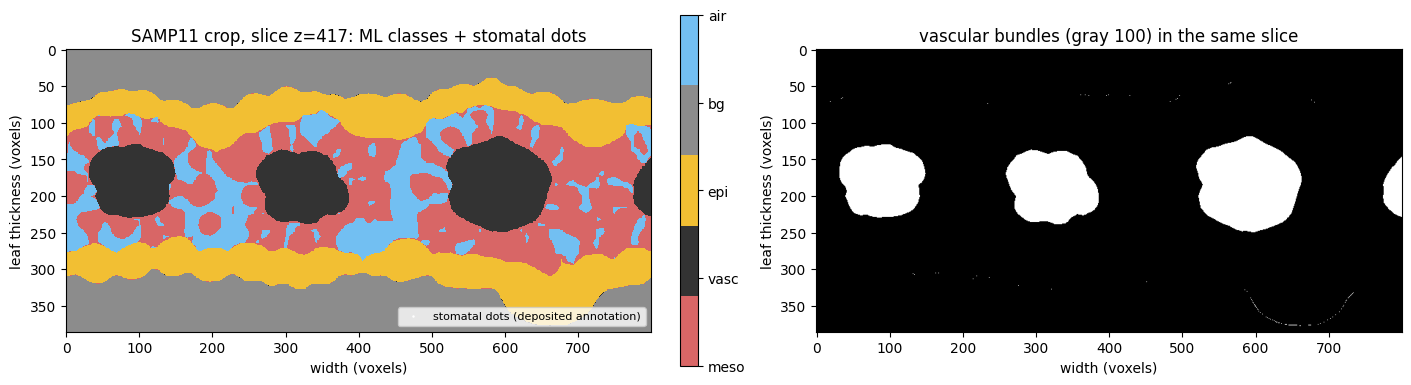

z-slice 417 chosen at the median stomatal dot; classes per deposit legend


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
Z_SHOW = int(np.median(np.argwhere(CD == 255)[:, 0]))
img = C[Z_SHOW]
dots = CD[Z_SHOW] == 255
cmap = ListedColormap([(0.85, 0.4, 0.4), (0.2, 0.2, 0.2), (0.95, 0.75, 0.2),
                       (0.55, 0.55, 0.55), (0.45, 0.75, 0.95)])
lut = np.zeros(256, np.uint8)
lut[0] = 0; lut[100] = 1; lut[152] = 2; lut[202] = 3; lut[255] = 4
lut[98] = 1; lut[99] = 1; lut[151] = 2; lut[201] = 3; lut[203] = 3
fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
im = axes[0].imshow(lut[img], cmap=cmap, vmin=0, vmax=4, interpolation="nearest")
axes[0].plot(np.nonzero(dots)[1], np.nonzero(dots)[0], ".", color="white", ms=1.5,
             label="stomatal dots (deposited annotation)")
axes[0].set_title(f"SAMP11 crop, slice z={Z_SHOW}: ML classes + stomatal dots")
axes[1].imshow((img == 100) | (img == 98) | (img == 99), cmap="gray")
axes[1].set_title("vascular bundles (gray 100) in the same slice")
for ax in axes:
    ax.set_xlabel("width (voxels)"); ax.set_ylabel("leaf thickness (voxels)")
axes[0].legend(loc="lower right", fontsize=8)
fig.colorbar(im, ax=axes[0], ticks=range(5), fraction=0.03).ax.set_yticklabels(
    ["meso", "vasc", "epi", "bg", "air"])
plt.savefig("/content/preview_input.png", dpi=110, bbox_inches="tight")
plt.show()
print("z-slice", Z_SHOW, "chosen at the median stomatal dot; classes per deposit legend")

**Port of MACRO_3A masks: air, mesophyll, epidermis, contact.** Air = class 255 kept as the
largest 3-D component (the `Purify` equivalent); mesophyll = class 0 largest component, white
top-hat (ball r=2) then dilation ×1, exactly as `Top Hat radius=2` + `Dilate` in MACRO_3A;
contact = dilated mesophyll AND air. The macro's `trimstack` edge-bias constants are applied to the
contact mask afterwards.（MACRO_3A の空気・葉肉・表皮マスクと contact を再現します。）

In [ ]:
import numpy as np, time
from scipy import ndimage as ndi
t0 = time.time()
air = C == 255
meso = C == 0
epi = C == 152
for name, m in [("air", air), ("meso", meso)]:
    lab, n = ndi.label(m)
    if n > 1:
        sizes = np.bincount(lab.ravel()); sizes[0] = 0
        biggest = lab == sizes.argmax()
        m[:] = biggest
        print(name, ": kept largest of", n, "3-D components (Purify equivalent)")
meso_dil = ndi.binary_dilation(meso, iterations=1)
contact = meso_dil & air
S0, S1, S2 = C.shape
W8 = S2 // 8
zkeep = np.zeros(S0, bool); zkeep[100:int(S0 * 0.95)] = True
xkeep = np.zeros(S2, bool); xkeep[W8:S2 - W8] = True
contact &= zkeep[:, None, None] & xkeep[None, None, :]
print("masks done in %.1f s" % (time.time() - t0))
print("contact voxels after trimstack-equivalent edge removal:", int(contact.sum()))
print("air voxels:", int(air.sum()), "| meso voxels:", int(meso.sum()), "| epi voxels:", int(epi.sum()))

air : kept largest of 300 3-D components (Purify equivalent)


meso : kept largest of 106351 3-D components (Purify equivalent)


masks done in 21.7 s
contact voxels after trimstack-equivalent edge removal: 2569043


air voxels: 24009382 | meso voxels: 54601506 | epi voxels: 56138279


**Port of MACRO_1: adaxial/abaxial split from vascular-bundle centroids.** Per cross-section
slice: label the vascular class (100) into components, keep those ≥ 4500 px (the macro's
`Analyze Particles size=4500-Infinity`), sort centroids by x, and mark everything above the
centroid polyline (linear interpolation, as the macro's polygon edges) as adaxial.
（MACRO_1 の血管束重心による AD/AB 分割を再現します。）

In [ ]:
import numpy as np
from scipy import ndimage as ndi
S0, S1, S2 = C.shape
AD = np.zeros(C.shape, bool)
vein_counts = np.zeros(S0, int)
YY = np.arange(S1)[:, None]
for z in range(S0):
    sl = C[z] == 100
    lab, n = ndi.label(sl)
    if n == 0:
        continue
    sizes = np.bincount(lab.ravel()); sizes[0] = 0
    keep = np.nonzero(sizes >= 4500)[0]
    vein_counts[z] = len(keep)
    if len(keep) == 0:
        continue
    com = np.array(ndi.center_of_mass(sl, lab, keep))
    order = np.argsort(com[:, 1])
    com = com[order]
    xs = np.concatenate([[0], com[:, 1], [S2 - 1]]).astype(float)
    ys = np.concatenate([[com[0, 0]], com[:, 0], [com[-1, 0]]]).astype(float)
    poly = np.interp(np.arange(S2), xs, ys)
    AD[z] = YY <= poly[None, :]
AB = ~AD
print("slices with veins:", int((vein_counts > 0).sum()), "/", S0,
      "| mean veins/slice: %.2f" % vein_counts.mean())
print("AD voxels:", int(AD.sum()), "| AB voxels:", int(AB.sum()))

slices with veins: 800 / 800 | mean veins/slice: 3.00


AD voxels: 119094431 | AB voxels: 127945569


**Region preview.** The same median cross-section with the AD/AB decision shown (warm = adaxial,
cool = abaxial), vascular outlines in black. Verify visually that the split follows the vascular
centroids as in MACRO_1.（AD/AB 分割の確認図です。）

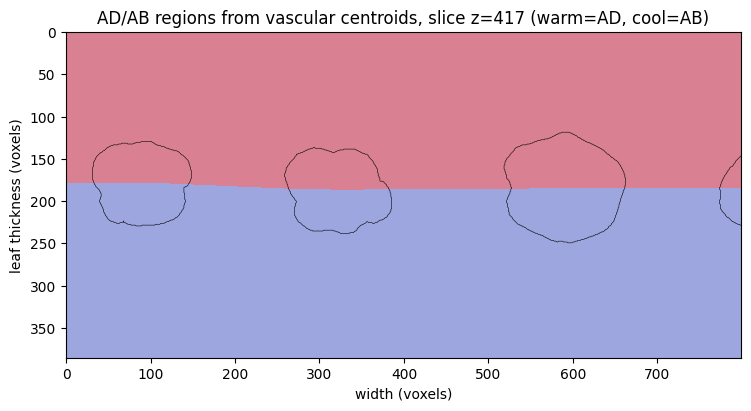

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
region = np.full(C[Z_SHOW].shape, np.nan)
region[AD[Z_SHOW]] = 1; region[AB[Z_SHOW]] = 0
ax.imshow(region, cmap="coolwarm", vmin=0, vmax=1, alpha=0.5, interpolation="nearest")
ax.contour(C[Z_SHOW] == 100, colors="k", linewidths=0.4)
ax.set_title(f"AD/AB regions from vascular centroids, slice z={Z_SHOW} (warm=AD, cool=AB)")
ax.set_xlabel("width (voxels)"); ax.set_ylabel("leaf thickness (voxels)")
plt.savefig("/content/preview_adab.png", dpi=110, bbox_inches="tight")
plt.show()

**Port of the MACRO_3A distance core (the heaviest cell).**
`Lgeo` — geodesic path length from the nearest stomatal dot through the airspace only
(multi-source Dijkstra over the 6-connected air graph; the author uses MorphoLibJ's Svensson
3,4,5,7 chamfer, an approximation of Euclidean length — the macro's ×0.343 converts voxel units
to µm). A 6-connected lattice path is marginally longer than a chamfer path; both approximate
the true geodesic.
`Leuc` — the same marker set but through an all-open mask (MACRO_3A's `blankSTACK`), i.e. the plain
Euclidean distance to the nearest dot. `Lepi` — Euclidean distance to the nearest epidermis voxel.
All three are restricted to the contact (the macro's multiply/divide-by-CONTACT idiom). Results are
stored float32 to fit the runtime memory.（MACRO_3A の距離計算の移植です。Lgeo は空気中の測地距離、
Leuc/Lepi はユークリッド距離です。）

In [ ]:
import numpy as np, time
from scipy import ndimage as ndi
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import dijkstra
from scipy.spatial import cKDTree
t0 = time.time()
SCALE_UM = 0.343  # MACRO_3A scaleSET for the deposited stacks
starts = np.argwhere(CD == 255)                    # all stomatal-dot voxels (MACRO_3A marker stack)
in_air = air[tuple(starts.T)]
starts_air = starts[in_air]
print("dot voxels:", len(starts), "| inside air:", len(starts_air), flush=True)
# --- Lgeo: multi-source Dijkstra over the 6-connected air graph (voxel units)
idx = np.full(C.shape, -1, np.int32)
n_air = int(air.sum())
idx[air] = np.arange(n_air, dtype=np.int32)
us, vs = [], []
for d in range(3):
    if d == 0:
        m = air[:-1, :, :] & air[1:, :, :]
        i0 = (slice(None, -1), slice(None), slice(None)); i1 = (slice(1, None), slice(None), slice(None))
    elif d == 1:
        m = air[:, :-1, :] & air[:, 1:, :]
        i0 = (slice(None), slice(None, -1), slice(None)); i1 = (slice(None), slice(1, None), slice(None))
    else:
        m = air[:, :, :-1] & air[:, :, 1:]
        i0 = (slice(None), slice(None), slice(None, -1)); i1 = (slice(None), slice(None), slice(1, None))
    us.append(idx[i0][m]); vs.append(idx[i1][m])
u = np.concatenate(us); v = np.concatenate(vs)
print("air graph: %d nodes, %d edges (%.1f s)" % (n_air, u.size, time.time() - t0), flush=True)
g = coo_matrix((np.ones(u.size, np.float32), (u, v)), shape=(n_air, n_air)).tocsr()
start_idx = idx[CD == 255]
start_idx = start_idx[start_idx >= 0]
dist = dijkstra(g, directed=False, indices=start_idx, min_only=True)
print("multi-source Dijkstra done %.1f s" % (time.time() - t0), flush=True)
Lgeo = np.full(C.shape, np.nan, dtype=np.float32)
Lgeo[air] = (dist * SCALE_UM).astype(np.float32)   # macro's x scaleSET voxel->um
Lgeo[~contact] = np.nan
del idx, g, u, v, us, vs, dist, start_idx
print("Lgeo mapped (%.1f s)" % (time.time() - t0), flush=True)
# --- Leuc / Lepi: exact Euclidean distances via KD-trees at the contact voxels only
contact_flat = np.flatnonzero(contact.ravel())
cz, cy, cx = np.unravel_index(contact_flat, C.shape)
pts = np.column_stack((cz, cy, cx)).astype(np.int64)
tree_dots = cKDTree(starts)
Leuc_v = tree_dots.query(pts, k=1, workers=2)[0].astype(np.float32)
Leuc_v *= SCALE_UM
print("Leuc (KD-tree, %d contact voxels) done %.1f s" % (len(pts), time.time() - t0), flush=True)
epi_pts = np.argwhere(epi)
tree_epi = cKDTree(epi_pts, balanced_tree=False, compact_nodes=False)
del epi_pts
Lepi_v = tree_epi.query(pts, k=1, workers=2)[0].astype(np.float32)
Lepi_v *= SCALE_UM
del tree_epi
print("Lepi (KD-tree) done %.1f s" % (time.time() - t0), flush=True)
with np.errstate(divide="ignore", invalid="ignore"):
    Tau_v = (Lgeo.ravel()[contact_flat] / Leuc_v) ** 2   # Eq 4, contact only
    Lam_v = Leuc_v / Lepi_v                              # Eq 5, contact only
Tau = np.full(C.shape, np.nan, np.float32); Tau.ravel()[contact_flat] = Tau_v
Lam = np.full(C.shape, np.nan, np.float32); Lam.ravel()[contact_flat] = Lam_v
print("tau/lambda done %.1f s | contact voxels with finite tau: %d" %
      (time.time() - t0, int(np.isfinite(Tau_v).sum())), flush=True)

dot voxels: 640 | inside air: 640


air graph: 24009382 nodes, 67965489 edges (6.1 s)


multi-source Dijkstra done 26.4 s


Lgeo mapped (27.8 s)


Leuc (KD-tree, 2569043 contact voxels) done 34.2 s


Lepi (KD-tree) done 77.6 s


tau/lambda done 78.2 s | contact voxels with finite tau: 2569043


**Trait maps (paper Fig. 5 style).** Paradermal mean projections (along the leaf-thickness
axis) of Lgeo and τ over the crop, with the stomatal dots marked. These are this notebook's own
visualizations of the ported maps, not author figures.（移植した距離マップの可視化です。）

/tmp/ipykernel_9042/425816634.py:8: RuntimeWarning: Mean of empty slice
  P = np.nanmean(M.astype(np.float64), axis=1)


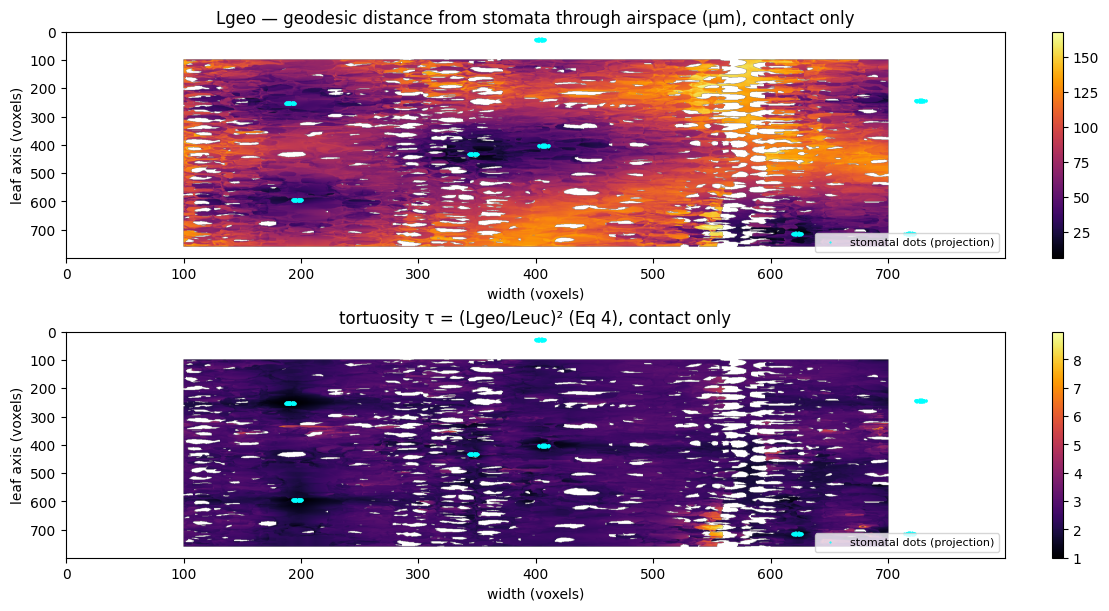

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
fig, axes = plt.subplots(2, 1, figsize=(11, 6), constrained_layout=True)
for ax, M, title in [
    (axes[0], Lgeo, "Lgeo — geodesic distance from stomata through airspace (µm), contact only"),
    (axes[1], Tau, "tortuosity τ = (Lgeo/Leuc)² (Eq 4), contact only"),
]:
    P = np.nanmean(M.astype(np.float64), axis=1)
    im = ax.imshow(P, aspect="auto", cmap="inferno")
    dz, dx = np.nonzero(np.nanmean((CD == 255).astype(float), axis=1) > 0)
    ax.plot(dx, dz, ".", color="cyan", ms=1.0, label="stomatal dots (projection)")
    ax.set_title(title); ax.set_xlabel("width (voxels)"); ax.set_ylabel("leaf axis (voxels)")
    ax.legend(loc="lower right", fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.03)
plt.savefig("/content/trait_maps.png", dpi=110, bbox_inches="tight")
plt.show()

**Port of MACRO_3B measurements.** Per-slice contact means (the `Plot Z-axis Profile` idiom:
per-slice mean over non-NaN contact voxels, then averaged across slices) for the whole crop and for
the AD/AB regions; porosity areas from voxel counts ×(0.343 µm)² using the macro's non-purified
masks; and the mesophyll (leaf-interior) height from a 2-D local-thickness approximation of BoneJ's
`Max Thick 2D`, averaged over all slices of this crop (the author's hard-coded slices 200–300 is
specific to their full-size stack).（MACRO_3B の測定値：スライス平均・AD/AB・面積・葉肉の厚さ。）

In [ ]:
import numpy as np, pandas as pd
from scipy import ndimage as ndi
VX = 0.343  # µm per voxel (MACRO_3A/3B scaleSET)
def region_mean(M, region=None):
    out = []
    for z in range(M.shape[0]):
        m = M[z] if region is None else np.where(region[z], M[z], np.nan)
        v = m[np.isfinite(m)]
        if v.size:
            out.append(v.mean())
    return float(np.mean(out))
air_np = C == 255   # MACRO_3B uses the NON-purified air mask
meso_np = C == 0
z_per_pt = contact_flat // (C.shape[1] * C.shape[2])
def region_mean_v(vec, region):
    out = []
    for z in range(C.shape[0]):
        m = (z_per_pt == z)
        if region is not None:
            m &= region.ravel()[contact_flat]
        v = vec[m & np.isfinite(vec)]
        if v.size:
            out.append(v.mean())
    return float(np.mean(out)) if out else float("nan")
traits = {}
for name, reg in [("SAMP", None), ("AD", AD), ("AB", AB)]:
    traits[f"{name}_Lgeo_um"] = region_mean(Lgeo, reg)
    traits[f"{name}_Leuc_um"] = region_mean_v(Leuc_v, reg)
    traits[f"{name}_Lepi_um"] = region_mean_v(Lepi_v, reg)
    traits[f"{name}_tau"] = region_mean(Tau, reg)
    traits[f"{name}_lambda"] = region_mean(Lam, reg)
traits["AIR_AREA_FULL_um2"] = float(air_np.sum()) * VX**2
traits["MESO_AREA_FULL_um2"] = float(meso_np.sum()) * VX**2
traits["AIR_AREA_AD_um2"] = float((air_np & AD).sum()) * VX**2
traits["MESO_AREA_AD_um2"] = float((meso_np & AD).sum()) * VX**2
traits["AIR_AREA_AB_um2"] = float((air_np & AB).sum()) * VX**2
traits["MESO_AREA_AB_um2"] = float((meso_np & AB).sum()) * VX**2
union = meso | air | (C == 100)
thick = [2 * ndi.distance_transform_edt(union[z], sampling=VX).max() for z in range(C.shape[0])]
traits["MESO_MASK_HEIGHT_um"] = float(np.mean(thick))
traits_tbl = pd.DataFrame([traits]).T.rename(columns={0: "value"})
traits_tbl

,value
SAMP_Lgeo_um,8.141457e+01
SAMP_Leuc_um,5.119909e+01
SAMP_Lepi_um,9.198024e+00
SAMP_tau,2.541352e+00
SAMP_lambda,1.471132e+01
AD_Lgeo_um,8.864822e+01
AD_Leuc_um,5.612402e+01
AD_Lepi_um,8.347659e+00
AD_tau,2.497402e+00
AD_lambda,1.740202e+01


**gias from paper Eqs 6–7** (Methods, "Airspace conductance"), applied exactly as printed:
gias = θ·D_m / ((L_meso·0.25)·τ·λ) with D_m = 1.51×10⁻⁵ m² s⁻¹ and the amphistomaty factor 0.25;
molar conversion via Eq 7 at P = 101,325 Pa and T = 25 °C. AD and AB rows use their regional θ, τ, λ
and the full-crop L_meso, mirroring MACRO_3B's single mesophyll-height value.
（論文の式6・7をそのまま適用し、gias を計算します。）

In [ ]:
D_M = 1.51e-5      # m^2 s^-1, diffusivity of CO2 in air (paper Methods)
P_PA = 101325.0    # Pa
T_C = 25.0         # deg C
def gias(theta, l_meso_um, tau, lam):
    g = theta * D_M / ((l_meso_um * 1e-6 * 0.25) * tau * lam)  # Eq 6, m/s
    g_mol = g * 44.6 * 273.16 * P_PA / ((273.16 + T_C) * 101325.0)  # Eq 7
    return g, g_mol
rows = []
for name in ["SAMP", "AD", "AB"]:
    ak = "FULL" if name == "SAMP" else name
    air_a = traits[f"AIR_AREA_{ak}_um2"]; meso_a = traits[f"MESO_AREA_{ak}_um2"]
    theta = air_a / (air_a + meso_a)
    g, g_mol = gias(theta, traits["MESO_MASK_HEIGHT_um"], traits[f"{name}_tau"], traits[f"{name}_lambda"])
    rows.append({"region": name, "porosity_theta": theta, "tau": traits[f"{name}_tau"],
                 "lambda": traits[f"{name}_lambda"], "Lgeo_um": traits[f"{name}_Lgeo_um"],
                 "Lepi_um": traits[f"{name}_Lepi_um"], "gias_m_s": g, "gias_mol_m2_s": g_mol})
gias_tbl = pd.DataFrame(rows).set_index("region")
gias_tbl

,porosity_theta,tau,lambda,Lgeo_um,Lepi_um,gias_m_s,gias_mol_m2_s
region,,,,,,,
SAMP,0.304635,2.541352,14.711324,81.414574,9.198024,0.008343,0.340895
AD,0.260953,2.497402,17.402021,88.648224,8.347659,0.006148,0.251208
AB,0.341446,2.589382,11.804541,73.601357,10.126859,0.011438,0.467342


**Per-slice conductance profile (paper Eq 8)** — an additional visualization created for this
notebook (not an author figure): Eq 6 applied per slice with that slice's contact-restricted τ, λ,
L_epi and whole-slice θ, then converted with Eq 7. This previews the depth-profile analysis the
authors run in MACRO_3C over full samples.
（おまけの可視化：スライスごとの gias 断面プロファイルです。）

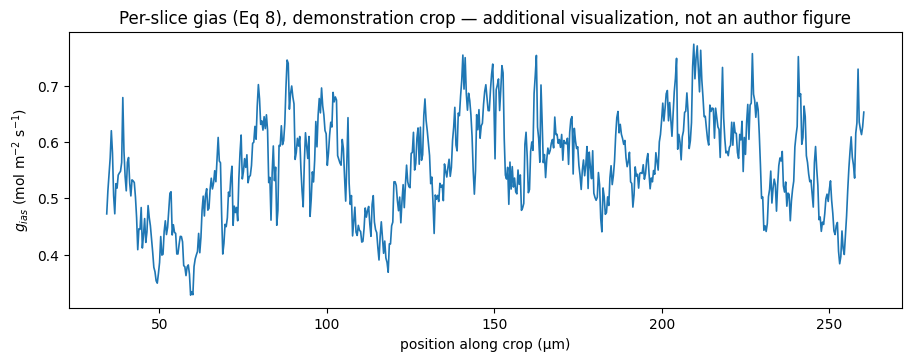

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
prof = []
for z in range(C.shape[0]):
    ok = np.isfinite(Tau[z])
    if not ok.sum():
        prof.append(np.nan); continue
    denom = ((air_np[z] | meso_np[z])).sum()
    th_z = air_np[z].sum() / denom if denom else np.nan
    tau_z = float(np.nanmean(Tau[z][ok])); lam_z = float(np.nanmean(Lam[z][ok]))
    lepi_z = float(np.mean(Lepi_v[(z_per_pt == z) & np.isfinite(Lepi_v)]))
    g = th_z * D_M / ((lepi_z * 1e-6) * tau_z * lam_z)  # Eq 8 uses L_epi[slice]
    prof.append(g * 44.6 * 273.16 * P_PA / ((273.16 + T_C) * 101325.0))
prof = np.array(prof)
fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
ax.plot(np.arange(len(prof)) * VX, prof, lw=1.2)
ax.set_xlabel("position along crop (µm)"); ax.set_ylabel(r"$g_{ias}$ (mol m$^{-2}$ s$^{-1}$)")
ax.set_title("Per-slice gias (Eq 8), demonstration crop — additional visualization, not an author figure")
plt.savefig("/content/gias_profile.png", dpi=110, bbox_inches="tight")
plt.show()

**Export the results table** to CSV inside the Colab VM (`/content`), next to the saved PNGs.
Learners can download it from the file browser.（結果表を CSV として保存します。）

In [ ]:
out = pd.concat([traits_tbl, gias_tbl], axis=0)
out.to_csv("/content/SAMP11_gias_traits.csv")
print(open("/content/SAMP11_gias_traits.csv").read())

,value,porosity_theta,tau,lambda,Lgeo_um,Lepi_um,gias_m_s,gias_mol_m2_s
SAMP_Lgeo_um,81.4145736694336,,,,,,,
SAMP_Leuc_um,51.19908905029297,,,,,,,
SAMP_Lepi_um,9.198023796081543,,,,,,,
SAMP_tau,2.5413522720336914,,,,,,,
SAMP_lambda,14.711323738098145,,,,,,,
AD_Lgeo_um,88.64822387695312,,,,,,,
AD_Leuc_um,56.12401580810547,,,,,,,
AD_Lepi_um,8.34765911102295,,,,,,,
AD_tau,2.4974021911621094,,,,,,,
AD_lambda,17.402021408081055,,,,,,,
AB_Lgeo_um,73.60135650634766,,,,,,,
AB_Leuc_um,45.866512298583984,,,,,,,
AB_Lepi_um,10.126858711242676,,,,,,,
AB_tau,2.5893824100494385,,,,,,,
AB_lambda,11.804540634155273,,,,,,,
AIR_AREA_FULL_um2,2826892.0547140003,,,,,,,
MESO_AREA_FULL_um2,6452716.585714001,,,,,,,
AIR_AREA_AD_um2,1107430.8605430003,,,,,,,
MESO_AREA_AD_um2,3136357.6314000003,,,,,,,
AIR_AREA_AB_um2,1719461.1941710003,,,,,,,
MESO_AREA_AB_um2,3316358.9543140004,,,,,,,
MESO_MASK_HEIGHT_um,58.99039452641353,,,,,,,
SAMP,,0.30463483582682815,2.5413522720336914,14.711323738098145,81.4145736694336,9.1

**Interpretation and limitations.**

- The executed scope is **one demonstration subvolume** of one deposited leaf sub-sample; it
  validates the *pipeline mechanics*, not the paper's dataset-level statistics. Values are not
  comparable to paper figures, which average 6–8 biological replicates × 2–3 technical replicates
  over full stacks.
- Expected direction check against the paper (Results, "Abaxial airspace had higher gias…"):
  abaxial τ and λ lower than adaxial, and abaxial gias greater — compare the AD/AB rows above.
- Deviations from the author's implementation are listed in the mapping table and the run report:
  exact geometric geodesic vs Svensson chamfer; 2×EDT local thickness vs BoneJ `Max Thick 2D`;
  full-crop thickness averaging vs the macro's hard-coded slice window; the demonstration
  subvolume itself; float32 storage.
- Mask R-CNN segmentation is NOT reproduced (no public weights); the deposited ML stacks are the
  input, exactly as in the authors' own trait pipeline. Crypt isolation (MACRO_2), depth-profile
  statistics and figure macros are out of scope.
- The author macros carry no license file (GitHub API license: null); the IJM source is fetched
  from the pinned commit for reference and the deposit data are CC BY.（結果の解釈と限界です。）

**References.**

1. Fischer M. et al. High-resolution microCT reveals relationships between stomata and interior
   leaf anatomy in sorghum. Plant Physiol. 2026;201(3):kiag414. doi:10.1093/plphys/kiag414.
   PMC13421375.
2. Leakey lab, microCT-Macros-Fischer, commit `9d7fcd2f417b9af686bf55a2ff81616adb316c4d`.
3. Illinois Data Bank, DOI 10.13012/B2IDB-8233295_V1 (CC BY): ML_STACKS.zip,
   microCT_REC2_META.csv, microCT_leaf_anatomy_Sorghum_readme.txt.
4. Niinemets Ü, Reichstein M. 2003 — molar conversion (Eq 7), as cited by the paper.
5. Legland D, Arganda-Carreras I, Andrey P. MorphoLibJ. Bioinformatics 2016 — the author's geodesic
   implementation (assessed headless in a diagnostic run; not used in this CPU port).